<a href="https://colab.research.google.com/github/henry09027/NTU-Course-MachineLearning/blob/main/Homework/HW2/Code/2026ML_HW2_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML HW2 - V2 (refined for a higher leaderboard score)

V1 results (validation accuracy / Kaggle public): E1 custom CNN 0.678 / 0.683, E5 pretrained ResNet-18 **0.707 / 0.702** (best), E2 no augmentation 0.574 / 0.574.
What those runs showed, and what V2 does about it:

| Observation in V1 | V2 response |
|---|---|
| E5 over-fits (train acc 98 %, val 70 %, val loss rising after epoch ~15) | **E9**: add CutMix (a stronger augmentation) to the same recipe; **E10-E12**: train on *all* 28.9 k labelled images (the 20 % validation split is also training data) |
| Single models only; the from-scratch CNN is a different kind of model from ResNet-18 | **E8**: ensemble of the already-trained V1 models (no training, takes minutes); **E13**: final ensemble of everything |
| Flip-TTA gave only +0.2 points | test-time augmentation with 10 views (flip + 4 shifts); the best level is picked on the validation set |
| Waiting for all runs before getting any CSV | every experiment now **downloads its CSV the moment it finishes** (Colab) |

**Bug fixed: class names.** The HW slide lists `5 = Neutral, 6 = Surprise`, but the sample images in the sanity-check cell and the class sizes (label 5 is the 11 % class) show the original FER-2013 order **`5 = Surprise, 6 = Neutral`**. `CLASS_NAMES` is corrected. Training and Kaggle scores are not affected (the model only sees numbers), but the V1 confusion-matrix figures and printouts in the appendix show those two names swapped. The cell "redraw the confusion matrices" in the V2 section regenerates them from `results.json` without any training.

**Deliberately not used** (guidelines): pseudo-labelling on the test images (it touches test data during training), and networks with attention blocks (ViT, EfficientNet / MobileNetV3 / RegNetY use squeeze-and-excitation). Only plain CNNs (ResNet-18 / 34 from torchvision, my own ResNet-style CNN) and allowed packages are used.

**How to run.** `Runtime > Run all` runs the setup cells and then the V2 experiments in order; the V1 runs live in the appendix at the end and are skipped (`RERUN_V1 = False`). V2 needs `results.json` and the checkpoints written by V1 (same `OUT_DIR`) for E8; if they are gone, E8 is skipped and E9 onwards still work. The experiment schedule that fits the 5-submissions-per-day limit is in the V2 section.

#### Download data


In [ ]:
!gdown 19oEShkdcBJf41nu46anyvu7BgXUffIGi
!unzip -q 'HW2.zip'

Downloading...
From (original): https://drive.google.com/uc?id=19oEShkdcBJf41nu46anyvu7BgXUffIGi
From (redirected): https://drive.google.com/uc?id=19oEShkdcBJf41nu46anyvu7BgXUffIGi&confirm=t&uuid=72003fab-20c0-4f05-9c0c-99e20ce95d7f
To: /content/HW2.zip
100% 52.1M/52.1M [00:02<00:00, 22.1MB/s]


#### Import packages

In [ ]:
import os
import copy
import json
import time
import random
import csv
import shutil
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd

import torchvision.transforms as T
from torchvision import models
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader, Subset
from PIL import Image
from argparse import Namespace
from tqdm import tqdm

#### Hyperparameters and setting

In [ ]:
# TODO: modify the hyperparameters
config = Namespace(
    random_seed = 42,
    BATCH = 128,
    n_epoch = 50,
    lr = 1e-3,              # peak LR of the one-cycle schedule
    weight_decay = 5e-2,
    label_smoothing = 0.1,
    dropout = 0.4,
    grad_clip = 1.0,
    num_workers = 2,
    ckpt_path = 'model.pth',
    # ---- added in V2 ----
    cutmix_prob = 0.0,      # chance that a training batch gets CutMix (0 = off, as in V1)
    cutmix_alpha = 1.0,
    channels_last = True,   # faster convolutions on the GPU (no effect on the result)
    fast = True,            # cudnn.benchmark on, deterministic off: faster, but runs are no longer bit-identical
)

# Where results.json / CSVs / figures / checkpoints are written.
# Colab wipes local files when the runtime disconnects. Since the experiments are spread over several days,
# mount Google Drive and point OUT_DIR at a folder there, e.g.
#   from google.colab import drive; drive.mount('/content/drive')
#   OUT_DIR = '/content/drive/MyDrive/ML_HW2'
OUT_DIR = '.'
os.makedirs(OUT_DIR, exist_ok=True)
def P(*parts):
    return os.path.join(OUT_DIR, *parts)

In [ ]:
TRA_PATH = 'data/train/'
TST_PATH = 'data/test/'
LABEL_PATH = 'data/train.csv'

# Label order of the data = original FER-2013 order. NOTE: the HW slide captions 5 as Neutral and 6 as Surprise,
# but the sample images (sanity-check cell below) and the class sizes show 5 = Surprise, 6 = Neutral.
CLASS_NAMES = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    fast = getattr(config, 'fast', False)
    torch.backends.cudnn.deterministic = not fast
    torch.backends.cudnn.benchmark = fast
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    random.seed(seed)
    np.random.seed(seed)

set_seed(config.random_seed)

#### Dataset and Dataloader

In [ ]:
class FaceExpressionDataset(Dataset):
    def __init__(self, img_path, label_path=None, tfm=T.ToTensor()):
        n_samples = len(os.listdir(img_path))
        if label_path is not None:
            self.images = [f'{img_path}/{i+7000}.jpg' for i in range(n_samples)]
            self.labels = pd.read_csv(label_path)['label'].values.tolist()
        else:
            self.images = [f'{img_path}/{i}.jpg' for i in range(n_samples)]
            self.labels = None
        # decode every image once and keep it in RAM (~150 MB for 36k grayscale 64x64 images),
        # so no epoch has to re-read / re-decode JPEG files
        self.imgs = [Image.open(p).convert('L') for p in self.images]
        self.tfm = tfm

    def __getitem__(self, idx):
        img = self.tfm(self.imgs[idx])
        if self.labels is not None:
            lab = torch.tensor(self.labels[idx]).long()
            return img, lab
        else:
            return img

    def __len__(self):
        return len(self.images)

In [ ]:
# TODO: define your augmentation for training and evaluation
MEAN, STD = (0.5,), (0.5,)   # grayscale images -> map [0, 1] to [-1, 1]

train_tfm = T.Compose([
    T.RandomHorizontalFlip(p=0.5),                                          # mirrored face = same emotion
    T.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1),
                    interpolation=T.InterpolationMode.BILINEAR),            # tilt / shift / distance changes
    T.ColorJitter(brightness=0.3, contrast=0.3),                            # lighting changes (grayscale: no hue/saturation)
    T.ToTensor(),
    T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.25, scale=(0.02, 0.12), value=0),                   # occlusion / watermark robustness
])
eval_tfm = T.Compose([
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

In [ ]:
def with_tfm(ds, tfm):
    """Shallow copy of a dataset: shares the cached images but uses a different transform."""
    new = copy.copy(ds)
    new.tfm = tfm
    return new

# images are decoded once; every experiment below reuses these two objects
full_train = FaceExpressionDataset(TRA_PATH, LABEL_PATH, tfm=eval_tfm)
test_dataset = FaceExpressionDataset(TST_PATH, tfm=eval_tfm)

# fixed 80/20 split -> identical train/valid images in every experiment, so validation numbers are comparable
perm = torch.randperm(len(full_train), generator=torch.Generator().manual_seed(config.random_seed)).tolist()
n_train = int(0.8 * len(full_train))
train_idx, valid_idx = perm[:n_train], perm[n_train:]
VAL_LABELS = np.array(full_train.labels)[valid_idx]      # labels of the validation split, in loader order

def build_loaders(use_aug=True, full=False, seed=None):
    """Training split uses train_tfm (or eval_tfm if use_aug=False). Validation and test never receive random augmentation.
    full=True trains on ALL labelled images (the validation split included) - used for the final models;
    the validation loader is then only a sanity check, no longer an honest estimate."""
    seed = config.random_seed if seed is None else seed
    tr_idx = list(range(len(full_train))) if full else train_idx
    train_set = Subset(with_tfm(full_train, train_tfm if use_aug else eval_tfm), tr_idx)
    valid_set = Subset(with_tfm(full_train, eval_tfm), valid_idx)
    kw = dict(batch_size=config.BATCH, num_workers=config.num_workers, pin_memory=True)
    train_loader = DataLoader(train_set, shuffle=True, drop_last=True,
                              persistent_workers=config.num_workers > 0,
                              generator=torch.Generator().manual_seed(seed), **kw)
    valid_loader = DataLoader(valid_set, shuffle=False, **kw)
    test_loader = DataLoader(test_dataset, shuffle=False, **kw)
    return train_loader, valid_loader, test_loader

train_loader, valid_loader, test_loader = build_loaders(use_aug=True)
print(f'train {len(train_idx)} | valid {len(valid_idx)} | test {len(test_dataset)}')

train 23109 | valid 5778 | test 7000


class counts in train.csv
  0 Angry       4009  (13.9%)
  1 Disgust      450  ( 1.6%)
  2 Fear        4136  (14.3%)
  3 Happy       7275  (25.2%)
  4 Sad         4841  (16.8%)
  5 Surprise    3221  (11.2%)
  6 Neutral     4955  (17.2%)


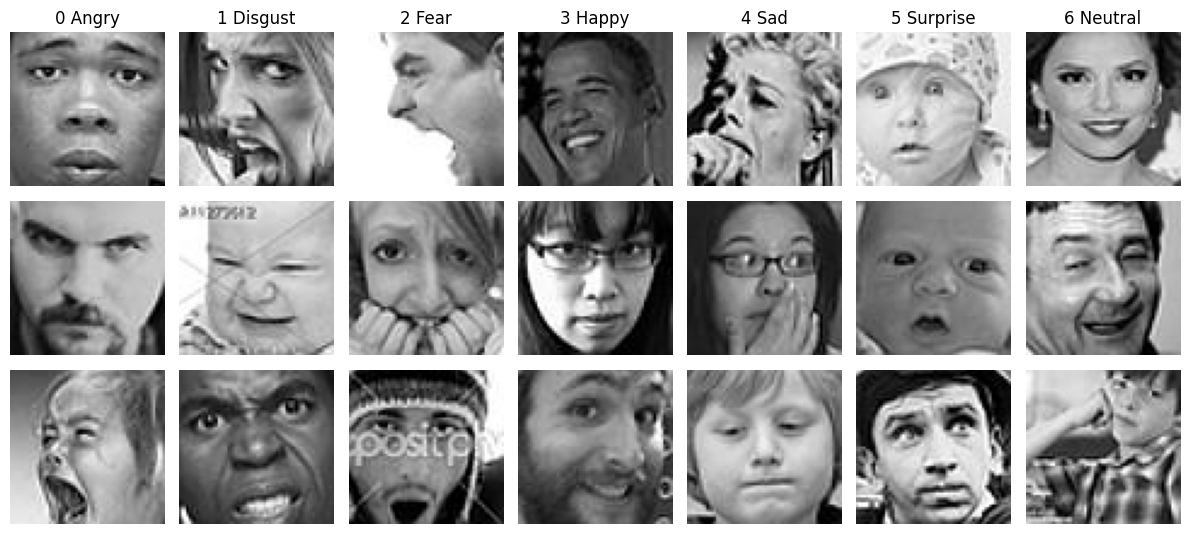

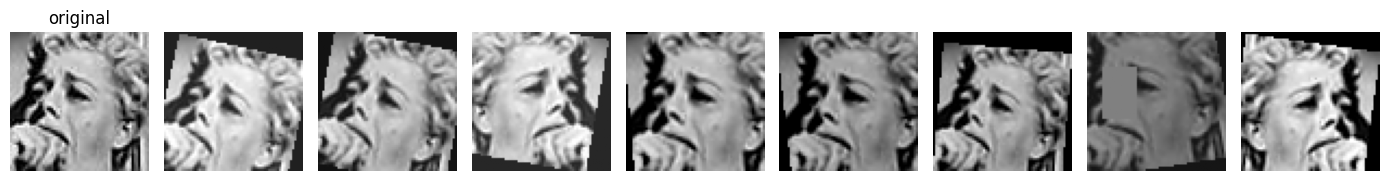

In [ ]:
# sanity checks: class balance, label order (compare with the slide), and what the augmentation does
labels_arr = np.array(full_train.labels)
print('class counts in train.csv')
for k, name in enumerate(CLASS_NAMES):
    print(f'  {k} {name:<9} {(labels_arr == k).sum():>6}  ({(labels_arr == k).mean() * 100:4.1f}%)')

fig, axes = plt.subplots(3, 7, figsize=(12, 5.5))
for k in range(7):
    for r, i in enumerate(np.where(labels_arr == k)[0][:3]):
        axes[r, k].imshow(full_train.imgs[i], cmap='gray', vmin=0, vmax=255)
        axes[r, k].axis('off')
        if r == 0:
            axes[r, k].set_title(f'{k} {CLASS_NAMES[k]}')
plt.tight_layout(); plt.show()

# one training image, 8 random augmentations
fig, axes = plt.subplots(1, 9, figsize=(14, 2))
axes[0].imshow(full_train.imgs[0], cmap='gray', vmin=0, vmax=255); axes[0].set_title('original'); axes[0].axis('off')
for a in axes[1:]:
    a.imshow(train_tfm(full_train.imgs[0])[0] * STD[0] + MEAN[0], cmap='gray', vmin=0, vmax=1); a.axis('off')
plt.tight_layout(); plt.show()

#### Model

In [ ]:
# TODO: define your CNN model
class ResBlock(nn.Module):
    """Two 3x3 conv layers (conv -> BN -> ReLU -> conv -> BN) + skip connection, then ReLU."""
    def __init__(self, cin, cout, stride=1, use_bn=True):
        super().__init__()
        norm = (lambda c: nn.BatchNorm2d(c)) if use_bn else (lambda c: nn.Identity())
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=not use_bn)
        self.bn1 = norm(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=not use_bn)
        self.bn2 = norm(cout)
        if stride != 1 or cin != cout:   # 1x1 projection so the skip path matches the new shape
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=not use_bn), norm(cout))
        else:
            self.shortcut = nn.Identity()
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        out = self.act(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.act(out + self.shortcut(x))


class FaceExpressionNet(nn.Module):
    # input 1x64x64 -> stem 64x64x64 -> stage1 64x64x64 -> stage2 128x32x32 -> stage3 256x16x16
    #   -> stage4 512x8x8 -> global average pooling (512) -> dropout -> Linear(512, 7)
    def __init__(self, num_classes=7, widths=(64, 128, 256, 512), use_bn=True, dropout=0.4):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(1, widths[0], 3, 1, 1, bias=not use_bn),
            nn.BatchNorm2d(widths[0]) if use_bn else nn.Identity(),
            nn.ReLU(inplace=True),
        )
        blocks, cin = [], widths[0]
        for i, w in enumerate(widths):
            blocks.append(ResBlock(cin, w, stride=1 if i == 0 else 2, use_bn=use_bn))
            cin = w
        self.stages = nn.Sequential(*blocks)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(widths[-1], num_classes),   # raw logits; CrossEntropyLoss applies log-softmax
        )
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.stages(self.stem(x)))


def count_params(model):
    return sum(p.numel() for p in model.parameters())

#### training loop

In [ ]:
def to_dev(x):
    x = x.to(device, non_blocking=True)
    if device.type == 'cuda' and x.dim() == 4 and getattr(config, 'channels_last', False):
        x = x.contiguous(memory_format=torch.channels_last)
    return x


def to_model_device(m):
    m.to(device)
    if device.type == 'cuda' and getattr(config, 'channels_last', False):
        m.to(memory_format=torch.channels_last)
    return m


def plot_curves(hist, tag):
    epochs = range(1, len(hist['train_loss']) + 1)
    plt.figure(figsize=(8, 6))
    plt.plot(epochs, hist['train_loss'], label='Training Loss')
    plt.plot(epochs, hist['valid_loss'], label='Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title(tag)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.savefig(P(f'curves_{tag}.png'), dpi=200, bbox_inches='tight')
    plt.show()


def cutmix(img, lab, alpha):
    """CutMix: paste a random box taken from a shuffled copy of the batch into every image.
    Returns the mixed images, the labels of the pasted parts and lam = share of the image that kept its own label."""
    H, W = img.shape[-2:]
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(img.size(0), device=img.device)
    r = np.sqrt(1.0 - lam)
    bh, bw = int(H * r), int(W * r)
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2 = max(cy - bh // 2, 0), min(cy + bh // 2, H)
    x1, x2 = max(cx - bw // 2, 0), min(cx + bw // 2, W)
    img[:, :, y1:y2, x1:x2] = img[idx, :, y1:y2, x1:x2]
    lam = 1.0 - (y2 - y1) * (x2 - x1) / (H * W)
    return img, lab[idx], lam


def train(model, train_loader, valid_loader, config, tag='E1_main', ckpt_path=None, select_best=True):
    """select_best=True : keep the epoch with the best validation accuracy (V1 behaviour).
    select_best=False: keep the last epoch (used when the validation split is part of the training data)."""
    ckpt = P(ckpt_path or config.ckpt_path)
    to_model_device(model)
    criteria = nn.CrossEntropyLoss(label_smoothing=config.label_smoothing)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=config.lr, weight_decay=config.weight_decay)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=config.lr, epochs=config.n_epoch,
        steps_per_epoch=len(train_loader), pct_start=0.1)
    use_amp = device.type == 'cuda'                      # mixed precision only on GPU
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    cutmix_prob = getattr(config, 'cutmix_prob', 0.0)

    best_acc, best_epoch = 0, 0
    hist = {'train_loss': [], 'valid_loss': [], 'train_acc': [], 'valid_acc': []}
    for epoch in range(config.n_epoch):
        # train
        model.train()
        train_loss, train_correct, n = 0, 0, 0
        for img, lab in tqdm(train_loader, leave=False):
            img, lab = to_dev(img), lab.to(device, non_blocking=True)
            use_cm = cutmix_prob > 0 and np.random.rand() < cutmix_prob
            if use_cm:
                img, lab_b, lam = cutmix(img, lab, config.cutmix_alpha)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                output = model(img)
                loss = criteria(output, lab)
                if use_cm:                                # mixed loss: lam * (own label) + (1 - lam) * (pasted label)
                    loss = lam * loss + (1 - lam) * criteria(output, lab_b)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params, config.grad_clip)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            train_loss += loss.item() * len(lab)
            train_correct += (torch.argmax(output, dim=-1) == lab).sum().item()
            n += len(lab)
        train_loss, train_acc = train_loss / n, train_correct / n   # (measured on augmented / mixed batches)
        hist['train_loss'].append(train_loss); hist['train_acc'].append(train_acc)
        print(f'Epoch: {epoch+1}/{config.n_epoch}, train loss: {train_loss:.4f}, train acc: {train_acc:.4f}')

        # valid
        model.eval()
        valid_loss, valid_correct, n = 0, 0, 0
        with torch.no_grad():
            for img, lab in valid_loader:
                img, lab = to_dev(img), lab.to(device, non_blocking=True)
                with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                    output = model(img)
                    loss = criteria(output, lab)
                valid_loss += loss.item() * len(lab)
                valid_correct += (torch.argmax(output, dim=-1) == lab).sum().item()
                n += len(lab)
        valid_loss, valid_acc = valid_loss / n, valid_correct / n
        hist['valid_loss'].append(valid_loss); hist['valid_acc'].append(valid_acc)
        print(f'Epoch: {epoch+1}/{config.n_epoch}, valid loss: {valid_loss:.4f}, valid acc: {valid_acc:.4f}')

        # update
        if select_best:
            if valid_acc > best_acc:
                best_acc, best_epoch = valid_acc, epoch + 1
                torch.save(model.state_dict(), ckpt)
                print(f'== best valid acc: {best_acc:.4f} ==')
        else:
            best_acc, best_epoch = valid_acc, epoch + 1
    if not select_best:
        torch.save(model.state_dict(), ckpt)
    model.load_state_dict(torch.load(ckpt, map_location=device))

    # plot the training/validation loss curve
    plot_curves(hist, tag)
    hist['best_valid_acc'], hist['best_epoch'] = best_acc, best_epoch
    return hist

In [ ]:
def tta_views(img, level):
    """level 0: the image; 1: + horizontal mirror; 2: + 4 diagonal shifts of 4 px (each also mirrored) = 10 views."""
    views = [img]
    if level >= 1:
        views.append(torch.flip(img, dims=[3]))
    if level >= 2:
        H, W = img.shape[-2:]
        pad = F.pad(img, (4, 4, 4, 4), mode='replicate')
        for dy, dx in ((0, 0), (0, 8), (8, 0), (8, 8)):
            crop = pad[:, :, dy:dy + H, dx:dx + W]
            views += [crop, torch.flip(crop, dims=[3])]
    return views


@torch.no_grad()
def predict_probs(model, loader, tta=0):
    """Softmax probabilities for every sample in `loader` (+ labels if the loader has them).
    tta = 0 / 1 / 2: number of test-time views, see tta_views (True counts as 1)."""
    to_model_device(model)
    model.eval()
    use_amp = device.type == 'cuda'
    probs, labels = [], []
    for batch in loader:
        if isinstance(batch, (list, tuple)):
            img, lab = batch
            labels += lab.tolist()
        else:
            img = batch
        img = to_dev(img)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            views = tta_views(img, int(tta))
            p = sum(model(v).float().softmax(dim=-1) for v in views) / len(views)
        probs.append(p.cpu())
    return torch.cat(probs).numpy(), np.array(labels)


def plot_confusion(cm, tag):
    """Draw a confusion matrix (rows: true class, columns: predicted) from an integer count matrix and print a text summary."""
    cm = np.asarray(cm)
    K = len(CLASS_NAMES)
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)   # row-normalised = per-class recall

    fig, ax = plt.subplots(figsize=(8.5, 7.5))
    im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right')
    ax.set_yticks(range(K)); ax.set_yticklabels(CLASS_NAMES)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f'{cm_norm[i, j]:.2f}\n({cm[i, j]})', ha='center', va='center', fontsize=8,
                    color='white' if cm_norm[i, j] > 0.5 else 'black')
    ax.set_xlabel('Predicted label'); ax.set_ylabel('True label')
    ax.set_title(f'Confusion matrix on validation set ({tag}), accuracy {np.trace(cm) / cm.sum():.4f}')
    fig.colorbar(im, ax=ax, fraction=0.046, label='fraction of true class')
    plt.tight_layout()
    plt.savefig(P(f'cm_{tag}.png'), dpi=200, bbox_inches='tight')
    plt.show()

    # text summary: helps to write the analysis in the report
    print('per-class recall (support):')
    for k in range(K):
        print(f'  {CLASS_NAMES[k]:<9} {cm_norm[k, k]:.3f}  ({cm[k].sum()})')
    off = sorted(((cm[i, j], i, j) for i in range(K) for j in range(K) if i != j), reverse=True)
    print('most frequent confusions (true -> predicted):')
    for count, i, j in off[:6]:
        print(f'  {CLASS_NAMES[i]:>8} -> {CLASS_NAMES[j]:<8} {count:>4}  ({count / max(cm[i].sum(), 1) * 100:.1f}% of true {CLASS_NAMES[i]})')


def draw_confusion_matrix(model, valid_loader, tag='E1_main'):
    probs, labels = predict_probs(model, valid_loader)
    predictions = probs.argmax(axis=1)
    K = len(CLASS_NAMES)
    cm = np.zeros((K, K), dtype=int)                      # rows: true class, columns: predicted class
    np.add.at(cm, (labels, predictions), 1)
    plot_confusion(cm, tag)
    return cm

In [ ]:
def deliver(path):
    """Download a finished file right away (Colab only), so it can be submitted while the next experiment is running."""
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        print('(not on Colab - the file stays at)', path)


def write_csv(predictions, out_csv, download=False):
    path = P(out_csv)
    os.makedirs(os.path.dirname(path) or '.', exist_ok=True),
    with open(path, 'w', newline='') as csvfile:
        writer = csv.writer(csvfile)
        writer.writerow(['id', 'label'])
        for id, r in enumerate(predictions):
            writer.writerow([id, r])
    print(f'wrote {path}  ({len(predictions)} rows)')
    if download:
        deliver(path)
    return path


def test(model, test_loader, out_csv='predict.csv', tta=0, download=False):
    probs, _ = predict_probs(model, test_loader, tta=tta)
    return write_csv(probs.argmax(axis=1).tolist(), out_csv, download)

In [ ]:
# ---- bookkeeping: results survive in results.json (set OUT_DIR to a Drive folder so they survive a Colab disconnect) ----
os.makedirs(P('submissions'), exist_ok=True)
RESULTS_PATH = P('results.json')
results = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
ENS_PATH = P('ensembles.json')
ens_results = json.load(open(ENS_PATH)) if os.path.exists(ENS_PATH) else {}

def save_results():
    json.dump(results, open(RESULTS_PATH, 'w'), indent=2)
    json.dump(ens_results, open(ENS_PATH, 'w'), indent=2)

def record(name, hist, cm, spec, aug, lr, n_params, ckpt, seconds=None, **extra):
    results[name] = dict(
        spec=spec, aug=aug, lr=lr, trainable_params=n_params, ckpt=ckpt,
        valid_acc=hist['best_valid_acc'], best_epoch=hist['best_epoch'],
        min_valid_loss=min(hist['valid_loss']), final_train_loss=hist['train_loss'][-1],
        final_valid_loss=hist['valid_loss'][-1],
        minutes=round(seconds / 60, 1) if seconds else None,
        history={k: hist[k] for k in ('train_loss', 'valid_loss', 'train_acc', 'valid_acc')},
        confusion_matrix=cm.tolist(), **extra)
    save_results()

def show_summary():
    rows = []
    for n, r in results.items():
        seen = r.get('full_data', False)
        rows.append(dict(experiment=n, aug=r['aug'], BN=r['spec']['use_bn'], dropout=r['spec']['dropout'],
                         arch=r['spec']['arch'] + ('(frozen)' if r['spec']['freeze_backbone'] else ''),
                         cutmix=r.get('cutmix_prob', 0.0), full_data=seen,
                         valid_acc='n/a (seen)' if seen else round(r['valid_acc'], 4),
                         valid_acc_tta=None if seen or r.get('valid_acc_tta') is None else round(r['valid_acc_tta'], 4),
                         tta=r.get('tta_level'), best_epoch=r['best_epoch'],
                         min_valid_loss=round(r['min_valid_loss'], 4), minutes=r['minutes']))
    print(pd.DataFrame(rows).to_string(index=False))
    for n, e in ens_results.items():
        print(f"\n{n}: valid acc {e['valid_acc']:.4f} ({e['note']}) members = {e['members']}")

def plot_aug_comparison(a='E1_main', b='E2_no_aug'):
    """The two sets of loss curves the report asks for, side by side on the same y-axis."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for ax, name, title in zip(axes, (a, b), ('With augmentation', 'Without augmentation')):
        h = results[name]['history']
        ep = range(1, len(h['train_loss']) + 1)
        ax.plot(ep, h['train_loss'], label='Training loss')
        ax.plot(ep, h['valid_loss'], label='Validation loss')
        ax.set_title(f"{title}  (best val acc {results[name]['valid_acc']:.4f})")
        ax.set_xlabel('Epochs'); ax.grid(alpha=0.3); ax.legend()
    axes[0].set_ylabel('Loss')
    plt.tight_layout()
    plt.savefig(P('curves_aug_vs_noaug.png'), dpi=200, bbox_inches='tight')
    plt.show()

In [ ]:
# ---- pretrained CNNs (ResNet-18 / 34) and a factory so every experiment builds its model the same way ----
class PretrainedResNet(nn.Module):
    """ImageNet ResNet adapted to 1x64x64 inputs (a plain CNN, so it respects the 'no attention' rule).
    - conv1: RGB filters are summed into one gray channel, stride 7x7/2 -> 7x7/1 and max-pool removed,
      otherwise layer4 would only see a 2x2 map for a 64x64 face.
    - fc: Dropout + Linear(512, 7).
    freeze_backbone=True trains only the new fc layer (BatchNorm statistics of the backbone stay fixed too)."""
    def __init__(self, arch='resnet18', num_classes=7, freeze_backbone=False, dropout=0.4):
        super().__init__()
        weights = {'resnet18': models.ResNet18_Weights.IMAGENET1K_V1,
                   'resnet34': models.ResNet34_Weights.IMAGENET1K_V1}[arch]
        net = getattr(models, arch)(weights=weights)                       # needs internet (fine on Colab)
        w = net.conv1.weight.data.sum(dim=1, keepdim=True)
        net.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=1, padding=3, bias=False)
        net.conv1.weight.data.copy_(w)
        net.maxpool = nn.Identity()
        net.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(net.fc.in_features, num_classes))
        if freeze_backbone:
            for name, p in net.named_parameters():
                p.requires_grad = name.startswith('fc')
        self.net = net
        self.freeze_backbone = freeze_backbone

    def train(self, mode=True):
        super().train(mode)
        if self.freeze_backbone:                       # keep frozen BatchNorm layers in eval mode
            for name, m in self.net.named_children():
                if name != 'fc':
                    m.eval()
        return self

    def forward(self, x):
        return self.net(x)


def build_model(arch='custom', use_bn=True, dropout=0.4, freeze_backbone=False):
    if arch == 'custom':
        return FaceExpressionNet(use_bn=use_bn, dropout=dropout)
    if arch in ('resnet18', 'resnet34'):
        return PretrainedResNet(arch, freeze_backbone=freeze_backbone, dropout=dropout)
    raise ValueError(arch)


best_tta_level = 1      # updated by every non-full run: the TTA level that was best on the validation split


def run_experiment(name, aug=True, arch='custom', use_bn=True, dropout=None, freeze_backbone=False, lr=None,
                   cutmix=None, full=False, seed=None, tta='auto'):
    """Train one configuration end-to-end: curves, confusion matrix, Kaggle CSV (downloaded immediately) and a results.json entry.
    cutmix : probability of CutMix per batch          full : train on all labelled images (validation split included)
    seed   : random seed of this run                  tta  : 'auto' = best level on validation (full runs: reuse best_tta_level), or 0/1/2"""
    global best_tta_level
    t0 = time.time()
    cfg = Namespace(**vars(config))
    if lr is not None:
        cfg.lr = lr
    if dropout is not None:
        cfg.dropout = dropout
    if cutmix is not None:
        cfg.cutmix_prob = cutmix
    if seed is not None:
        cfg.random_seed = seed
    spec = dict(arch=arch, use_bn=use_bn, dropout=cfg.dropout, freeze_backbone=freeze_backbone)

    set_seed(cfg.random_seed)
    tr_loader, va_loader, te_loader = build_loaders(use_aug=aug, full=full, seed=cfg.random_seed)
    m = build_model(**spec)
    n_params = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f'[{name}] aug={aug} {spec} lr={cfg.lr} cutmix={cfg.cutmix_prob} full_data={full} seed={cfg.random_seed} '
          f'trainable params={n_params / 1e6:.2f}M')

    ckpt = f'ckpt_{name}.pth'
    hist = train(m, tr_loader, va_loader, cfg, tag=name, ckpt_path=ckpt, select_best=not full)
    cm_ = draw_confusion_matrix(m, va_loader, tag=name) if not full else np.zeros((len(CLASS_NAMES),) * 2, dtype=int)

    # test-time augmentation level
    if tta == 'auto' and not full:
        accs = {}
        for lv in (0, 1, 2):
            p, _ = predict_probs(m, va_loader, tta=lv)
            accs[lv] = float((p.argmax(axis=1) == VAL_LABELS).mean())
        level = max(accs, key=lambda lv: (accs[lv], -lv))          # ties -> cheaper level
        best_tta_level = level
        print('valid acc by TTA level (0 none, 1 flip, 2 flip + shifts):', {k: round(v, 4) for k, v in accs.items()})
    elif tta == 'auto':
        level = best_tta_level
    else:
        level = int(tta)
    pv, _ = predict_probs(m, va_loader, tta=level)
    pt, _ = predict_probs(m, te_loader, tta=level)
    os.makedirs(P('probs'), exist_ok=True)
    np.save(P('probs', f'{name}_L{level}_val.npy'), pv)
    np.save(P('probs', f'{name}_L{level}_test.npy'), pt)
    path = write_csv(pt.argmax(axis=1).tolist(), f'submissions/{name}.csv', download=True)

    record(name, hist, cm_, spec, aug, cfg.lr, n_params, ckpt, time.time() - t0,
           cutmix_prob=cfg.cutmix_prob, full_data=full, seed=cfg.random_seed, tta_level=level,
           valid_acc_tta=float((pv.argmax(axis=1) == VAL_LABELS).mean()))
    note = 'val split was used for training -> not an honest estimate' if full else f'TTA level {level}: {results[name]["valid_acc_tta"]:.4f}'
    print(f'[{name}] best valid acc {hist["best_valid_acc"]:.4f} at epoch {hist["best_epoch"]}  ({note})')
    print(f'>>> SUBMIT NOW: {path}  (already downloaded to your computer)')

In [ ]:
# ---- ensembling utilities: average the softmax outputs of several finished models ----
def get_probs(name, split, level):
    """Class probabilities of experiment `name` on 'val' or 'test' with TTA `level`; cached in probs/*.npy.
    If only a checkpoint exists (the V1 runs), the probabilities are computed from it."""
    path = P('probs', f'{name}_L{level}_{split}.npy')
    if not os.path.exists(path):
        r = results[name]
        ck = P(r['ckpt'])
        if not os.path.exists(ck):
            raise FileNotFoundError(f'no checkpoint for {name}: {ck}')
        m = build_model(**r['spec'])
        m.load_state_dict(torch.load(ck, map_location=device))
        _, va_loader, te_loader = build_loaders(use_aug=False)
        os.makedirs(P('probs'), exist_ok=True)
        for sp, ld in (('val', va_loader), ('test', te_loader)):
            p, _ = predict_probs(m, ld, tta=level)
            np.save(P('probs', f'{name}_L{level}_{sp}.npy'), p)
        del m
    return np.load(path)


def val_acc(p):
    return float((p.argmax(axis=1) == VAL_LABELS).mean())


def val_nll(p):
    return float(-np.log(p[np.arange(len(VAL_LABELS)), VAL_LABELS] + 1e-9).mean())


def greedy_ensemble(names, level, max_steps=15):
    """Forward selection with replacement on the validation split: repeatedly add the model that helps most
    (a model picked twice gets twice the weight). Returns (members, validation accuracy)."""
    pv = {n: get_probs(n, 'val', level) for n in names}
    chosen, total, best = [], 0, (-1.0, [])
    for _ in range(max_steps):
        cands = []
        for n in names:
            p = (total + pv[n]) / (len(chosen) + 1)
            cands.append((val_acc(p), -val_nll(p), n))
        acc, _, n = max(cands)
        chosen.append(n)
        total = total + pv[n]
        if acc > best[0]:
            best = (acc, list(chosen))
    return best[1], best[0]


def ensemble_to_csv(name, members, level, note):
    """Write submissions/<name>.csv from the averaged test probabilities of `members` and download it."""
    pt = sum(get_probs(n, 'test', level) for n in members) / len(members)
    path = write_csv(pt.argmax(axis=1).tolist(), f'submissions/{name}.csv', download=True)
    pv = sum(get_probs(n, 'val', level) for n in members) / len(members)
    ens_results[name] = dict(members=members, level=level, valid_acc=val_acc(pv), note=note)
    save_results()
    print(f'[{name}] valid acc {val_acc(pv):.4f} ({note})')
    print(f'>>> SUBMIT NOW: {path}  (already downloaded to your computer)')

---
# V2 experiments (new)

Every experiment below ends with `>>> SUBMIT NOW: <file>`: the CSV has already been downloaded by then, so submit it to Kaggle while the next experiment trains.
Validation numbers of E8 / E9 are honest (those models never saw the validation split). **E10-E12 train on all labelled images, so their own validation accuracy is meaningless** (marked `n/a (seen)`); judge them by the Kaggle public score.

| ID | What | Why | Time (my estimate from your V1 timings) |
|----|------|-----|------|
| E8_ens_v1 | ensemble of the finished V1 models (E1, E3, E4, E5), greedy weights chosen on the validation split, flip TTA | models of different kinds make different mistakes; costs no training | 2-4 min |
| E9_r18_cutmix | E5 recipe + CutMix (p = 0.5) | E5 over-fits strongly, CutMix is a stronger augmentation; single change vs E5 so the effect is measurable | ~28 min |
| E10_r18_full_s42 | ResNet-18, all 28.9 k images, recipe of E5 or E9 (whichever has the higher validation accuracy) | 25 % more data | ~35 min |
| E11_r18_full_s7 | same, different seed | a second ensemble member | ~35 min |
| E12_r34_full | ResNet-34 (torchvision, no attention), all images | a deeper, different member (off by default) | ~70 min |
| E13_final_ens | equal-weight average of E5/E9 (if >= 0.69 val) and all full-data models | final submission | 3-5 min |

**Schedule for the limit of 5 submissions per day** (Kaggle and NTU COOL close on 10/30 23:59 UTC+8):

| Day | Run | Submit |
|-----|-----|--------|
| Today | E8, E9 | E8 first (it needs no training), then E9 |
| Tomorrow | E10, E11, E13 | E10, E11, E13 (3 of 5) |
| Optional | E12, then run E13 again | E12 and the new E13 |

Switches for `Run all` (set to False to skip):

In [ ]:
RUN_E8, RUN_E9, RUN_E10, RUN_E11, RUN_E12, RUN_E13 = True, True, True, True, False, True
REDRAW = ['E1_main', 'E5_resnet18_finetune']      # confusion matrices to redraw with the corrected class names

### Redraw the confusion matrices with the corrected class names (no training, uses results.json)

In [ ]:
for name in REDRAW:
    if name in results and np.array(results[name]['confusion_matrix']).sum() > 0:
        plot_confusion(results[name]['confusion_matrix'], name)      # overwrites cm_<name>.png used in the report
    else:
        print(f'{name}: not in results.json (V1 results not found in OUT_DIR)')

E1_main: not in results.json (V1 results not found in OUT_DIR)
E5_resnet18_finetune: not in results.json (V1 results not found in OUT_DIR)


### E8 - ensemble of the finished V1 models (free)

In [ ]:
if RUN_E8:
    V1_MODELS = ('E1_main', 'E3_no_bn', 'E4_no_dropout', 'E5_resnet18_finetune')
    cands = [n for n in V1_MODELS if n in results and os.path.exists(P(results[n]['ckpt']))]
    if len(cands) < 2:
        print('V1 checkpoints / results.json not found in OUT_DIR -> E8 skipped (E9 onwards do not need them).')
    else:
        for n in cands:
            print(f'{n:<24} single model, flip TTA: valid acc {val_acc(get_probs(n, "val", 1)):.4f}')
        print(f'equal weights over all {len(cands)}      : valid acc {val_acc(sum(get_probs(n, "val", 1) for n in cands) / len(cands)):.4f}')
        members, acc = greedy_ensemble(cands, level=1)
        print('greedy selection:', members, f'-> valid acc {acc:.4f}')
        ensemble_to_csv('E8_ens_v1', members, level=1, note='greedy weights picked on the validation split, flip TTA')

V1 checkpoints / results.json not found in OUT_DIR -> E8 skipped (E9 onwards do not need them).


### E9 - pretrained ResNet-18 + CutMix (single change compared with E5)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 165MB/s]


[E9_r18_cutmix] aug=True {'arch': 'resnet18', 'use_bn': True, 'dropout': 0.4, 'freeze_backbone': False} lr=0.0005 cutmix=0.5 full_data=False seed=42 trainable params=11.17M


Epoch: 1/50, train loss: 1.8646, train acc: 0.2888


Epoch: 1/50, valid loss: 1.4691, valid acc: 0.4860
== best valid acc: 0.4860 ==


Epoch: 2/50, train loss: 1.5979, train acc: 0.4323


... (93 outputs left out)

Epoch: 49/50, train loss: 0.9480, train acc: 0.7790


Epoch: 49/50, valid loss: 1.1459, valid acc: 0.7056


Epoch: 50/50, train loss: 0.9381, train acc: 0.7751


Epoch: 50/50, valid loss: 1.1638, valid acc: 0.7030


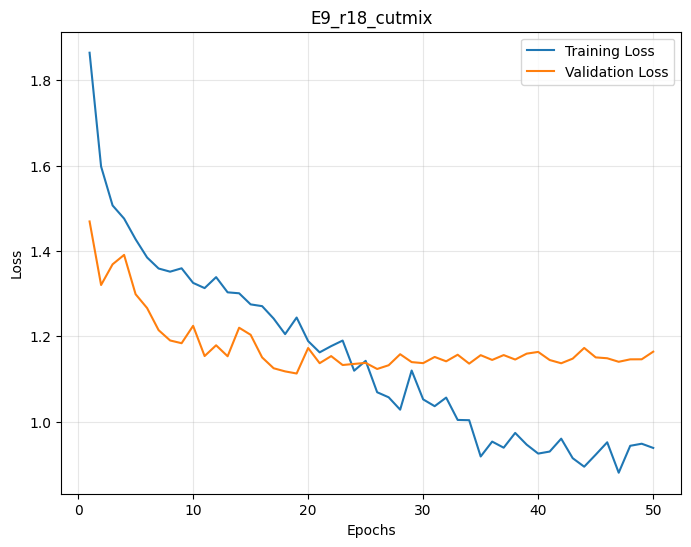

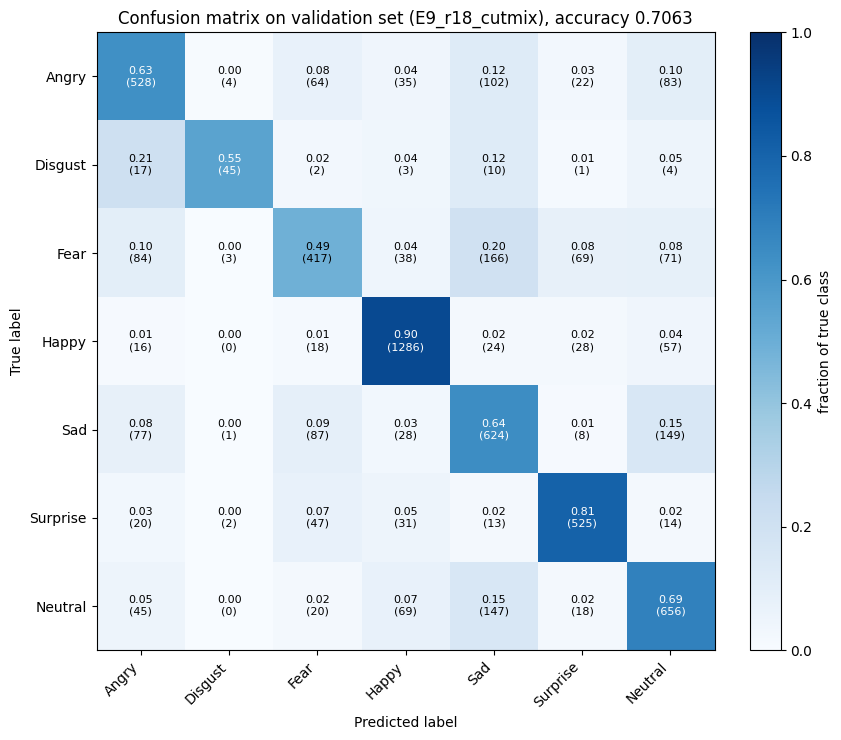

per-class recall (support):
  Angry     0.630  (838)
  Disgust   0.549  (82)
  Fear      0.492  (848)
  Happy     0.900  (1429)
  Sad       0.641  (974)
  Surprise  0.805  (652)
  Neutral   0.687  (955)
most frequent confusions (true -> predicted):
      Fear -> Sad       166  (19.6% of true Fear)
       Sad -> Neutral   149  (15.3% of true Sad)
   Neutral -> Sad       147  (15.4% of true Neutral)
     Angry -> Sad       102  (12.2% of true Angry)
       Sad -> Fear       87  (8.9% of true Sad)
      Fear -> Angry      84  (9.9% of true Fear)
valid acc by TTA level (0 none, 1 flip, 2 flip + shifts): {0: 0.7063, 1: 0.7129, 2: 0.7111}
wrote ./submissions/E9_r18_cutmix.csv  (7000 rows)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[E9_r18_cutmix] best valid acc 0.7063 at epoch 42  (TTA level 1: 0.7129)
>>> SUBMIT NOW: ./submissions/E9_r18_cutmix.csv  (already downloaded to your computer)


In [19]:
if RUN_E9:
    run_experiment('E9_r18_cutmix', arch='resnet18', lr=5e-4, cutmix=0.5)

### E10 / E11 - ResNet-18 on all labelled images (two seeds)
The recipe (with or without CutMix) is chosen automatically from the validation accuracies of E5 and E9.
No checkpoint selection is possible without a held-out set, so the last epoch is used (in E5 the last epoch was within 0.2 points of the best one).

recipe for the full-data runs: ResNet-18 plain (E5 recipe)
[E10_r18_full_s42] aug=True {'arch': 'resnet18', 'use_bn': True, 'dropout': 0.4, 'freeze_backbone': False} lr=0.0005 cutmix=0.0 full_data=True seed=42 trainable params=11.17M


Epoch: 1/50, train loss: 1.7612, train acc: 0.3481


Epoch: 1/50, valid loss: 1.3764, valid acc: 0.5386


Epoch: 2/50, train loss: 1.3951, train acc: 0.5352


Epoch: 2/50, valid loss: 1.3022, valid acc: 0.5881


Epoch: 3/50, train loss: 1.2995, train acc: 0.5855


... (91 outputs left out)

Epoch: 49/50, train loss: 0.5311, train acc: 0.9744


Epoch: 49/50, valid loss: 0.5034, valid acc: 0.9879


Epoch: 50/50, train loss: 0.5319, train acc: 0.9752


Epoch: 50/50, valid loss: 0.5044, valid acc: 0.9872


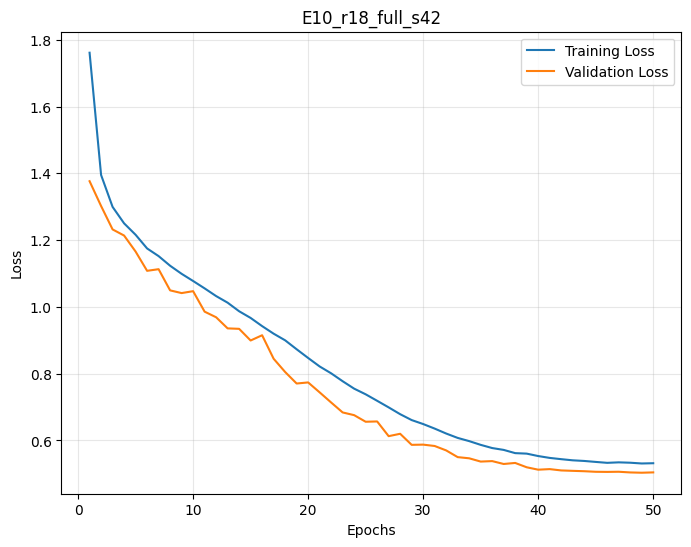

wrote ./submissions/E10_r18_full_s42.csv  (7000 rows)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[E10_r18_full_s42] best valid acc 0.9872 at epoch 50  (val split was used for training -> not an honest estimate)
>>> SUBMIT NOW: ./submissions/E10_r18_full_s42.csv  (already downloaded to your computer)
recipe for the full-data runs: ResNet-18 plain (E5 recipe)
[E11_r18_full_s7] aug=True {'arch': 'resnet18', 'use_bn': True, 'dropout': 0.4, 'freeze_backbone': False} lr=0.0005 cutmix=0.0 full_data=True seed=7 trainable params=11.17M


Epoch: 1/50, train loss: 1.7306, train acc: 0.3531


Epoch: 1/50, valid loss: 1.4279, valid acc: 0.5151


... (94 outputs left out)

Epoch: 49/50, train loss: 0.5335, train acc: 0.9752


Epoch: 49/50, valid loss: 0.5074, valid acc: 0.9860


Epoch: 50/50, train loss: 0.5352, train acc: 0.9726


Epoch: 50/50, valid loss: 0.5077, valid acc: 0.9858


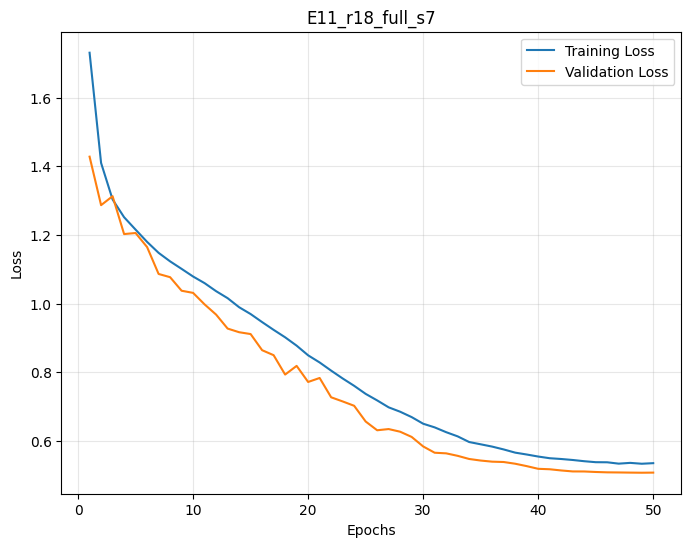

wrote ./submissions/E11_r18_full_s7.csv  (7000 rows)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[E11_r18_full_s7] best valid acc 0.9858 at epoch 50  (val split was used for training -> not an honest estimate)
>>> SUBMIT NOW: ./submissions/E11_r18_full_s7.csv  (already downloaded to your computer)


In [20]:
def full_recipe_cutmix():
    ok = 'E9_r18_cutmix' in results and 'E5_resnet18_finetune' in results
    use = ok and results['E9_r18_cutmix']['valid_acc'] > results['E5_resnet18_finetune']['valid_acc']
    print('recipe for the full-data runs:', 'ResNet-18 + CutMix (E9 beat E5)' if use else 'ResNet-18 plain (E5 recipe)')
    return 0.5 if use else 0.0

if RUN_E10:
    run_experiment('E10_r18_full_s42', arch='resnet18', lr=5e-4, cutmix=full_recipe_cutmix(), full=True, seed=42)
if RUN_E11:
    run_experiment('E11_r18_full_s7', arch='resnet18', lr=5e-4, cutmix=full_recipe_cutmix(), full=True, seed=7)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
df.to_csv('/content/drive/MyDrive/E10_r18_full_s42.csv', index=False)


### E12 (optional, off by default) - ResNet-34 on all labelled images
A deeper network as a different ensemble member. It has not been validated on the split, so check its Kaggle public score before relying on it; it takes about twice as long as E10.

In [21]:
if RUN_E12:
    run_experiment('E12_r34_full', arch='resnet34', lr=5e-4, cutmix=full_recipe_cutmix(), full=True, seed=42)

### E13 - final ensemble
Equal-weight average of: every held-out-validated model with validation accuracy >= 0.69 (E5, and E9 if it reached that) and every full-data model.
Re-run this cell after E12 to include it. The printed validation accuracy only uses the models that did not train on the validation split.

In [22]:
if RUN_E13:
    ok = lambda n: os.path.exists(P(results[n]['ckpt']))
    split_models = [n for n, r in results.items() if not r.get('full_data') and r['valid_acc'] >= 0.69 and r['spec']['arch'] != 'custom' and ok(n)]
    full_models = [n for n, r in results.items() if r.get('full_data') and ok(n)]
    members = split_models + full_models
    print('split-trained members:', split_models)
    print('full-data members    :', full_models)
    if len(members) < 2:
        print('need at least two finished members -> run E9-E11 first')
    else:
        if len(split_models) >= 2:
            pv = sum(get_probs(n, 'val', best_tta_level) for n in split_models) / len(split_models)
            print(f'honest validation accuracy of the split-trained part: {val_acc(pv):.4f}')
        ensemble_to_csv('E13_final_ens', members, level=best_tta_level,
                        note='includes full-data models, so this number is optimistic' if full_models else 'split-trained models only')

split-trained members: ['E9_r18_cutmix']
full-data members    : ['E10_r18_full_s42', 'E11_r18_full_s7']
wrote ./submissions/E13_final_ens.csv  (7000 rows)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[E13_final_ens] valid acc 0.9848 (includes full-data models, so this number is optimistic)
>>> SUBMIT NOW: ./submissions/E13_final_ens.csv  (already downloaded to your computer)


### Collect everything for the report

In [23]:
show_summary()

# backup bundle (the CSVs were already downloaded one by one)
shutil.make_archive(P('submissions'), 'zip', P('submissions'))
assets = P('report_assets')
os.makedirs(assets, exist_ok=True)
for f in os.listdir(OUT_DIR):
    if f.endswith('.png') or f in ('results.json', 'ensembles.json'):
        shutil.copy(P(f), os.path.join(assets, f))
shutil.make_archive(P('report_assets'), 'zip', assets)
try:
    from google.colab import files
    files.download(P('submissions.zip'))
    files.download(P('report_assets.zip'))
except ImportError:
    print('Not on Colab: see', P('submissions.zip'), 'and', P('report_assets.zip'))

      experiment  aug   BN  dropout     arch  cutmix  full_data  valid_acc  valid_acc_tta  tta  best_epoch  min_valid_loss  minutes
   E9_r18_cutmix True True      0.4 resnet18     0.5      False     0.7063         0.7129    1          42          1.1126     22.9
E10_r18_full_s42 True True      0.4 resnet18     0.0       True n/a (seen)            NaN    1          50          0.5034     27.1
 E11_r18_full_s7 True True      0.4 resnet18     0.0       True n/a (seen)            NaN    1          50          0.5074     27.3

E13_final_ens: valid acc 0.9848 (includes full-data models, so this number is optimistic) members = ['E9_r18_cutmix', 'E10_r18_full_s42', 'E11_r18_full_s7']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Appendix - V1 runs (E1-E7), kept for the record

These are the cells that produced the V1 results (outputs are the original ones). They are skipped by `Run all` because `RERUN_V1 = False`.
**Note:** the confusion matrices and per-class printouts in these outputs show the names of classes 5 and 6 swapped (5 is Surprise, 6 is Neutral); the numbers themselves are correct.

In [24]:
RERUN_V1 = False    # set True to train E1-E7 again (about 2 hours)

### Training

In [25]:
if RERUN_V1:
    set_seed(config.random_seed)
    model = FaceExpressionNet(dropout=config.dropout)
    print(f'parameters: {count_params(model) / 1e6:.2f} M')
    main_hist = train(model, train_loader, valid_loader, config, tag='E1_main')

In [26]:
if RERUN_V1:
    cm = draw_confusion_matrix(model, valid_loader, tag='E1_main')

### Testing

In [27]:
if RERUN_V1:
    model.load_state_dict(torch.load(P(config.ckpt_path), map_location=device))
    test(model, test_loader)

---
# Experiments for the report

Every experiment trains with the **same seed, same train/valid split, same hyper-parameters** and changes exactly one thing.
Each run leaves behind: `curves_<name>.png` (loss curves), `cm_<name>.png` (confusion matrix), `submissions/<name>.csv` (Kaggle file) and an entry in `results.json`.
The **validation accuracy printed here is free** (it costs no Kaggle submission), so every comparison in the report can be made with it; the Kaggle score is a bonus column.

| ID | What changes | Report section it feeds | Kaggle priority |
|----|--------------|-------------------------|-----------------|
| E1_main | main model: BN + dropout + augmentation (the run above) | CNN model, confusion matrix, augmentation (with) | **must** |
| E2_no_aug | same, but no augmentation | augmentation (without) | **must** |
| E3_no_bn | same as E1, BatchNorm removed | CNN model (b) BN | should |
| E4_no_dropout | same as E1, dropout p = 0 | CNN model (b) dropout | should |
| E5_resnet18_finetune | ImageNet-pretrained ResNet-18, all layers fine-tuned | CNN model (c) | nice to have |
| E6_resnet18_frozen | same, backbone frozen, only the new head trained | CNN model (c) | nice to have |
| E7_main_tta | E1 weights + horizontal-flip test-time augmentation | final polish | if public score is not comfortably above 0.66257 |

**Kaggle limit = 5 submissions per day (the limit resets at 00:00 UTC, as far as I know). Suggested schedule:**

| Day | Run on Colab (about 10-15 min per run on a T4; my estimate) | Submit |
|-----|------|--------|
| Day 1 | E1 (already done above), E2, E4, E3 | E1 first (it already tells you whether you beat both baselines), then E2, E4, E3. Uses 4 of 5, one spare for a format mistake. |
| Day 2 | E5, E6, E7 | E7, E5, E6. Uses 3 of 5. |
| Day 3 and later | nothing planned | spare slots, only needed if a score is below the baseline. Kaggle and NTU COOL both close on 10/30 23:59 (UTC+8), i.e. 15:59 UTC. |

If time or GPU quota is short, drop in this order: E6, E5, E3, E4, E7. E1 and E2 are enough for the graded parts.

### E1 - main model (already trained above, nothing is retrained)

In [28]:
if RERUN_V1:
    shutil.copy(P('predict.csv'), P('submissions', 'E1_main.csv'))
    record('E1_main', main_hist, cm,
           dict(arch='custom', use_bn=True, dropout=config.dropout, freeze_backbone=False),
           True, config.lr, count_params(model), config.ckpt_path)
    show_summary()

### E2 - no data augmentation (report: Data Augmentation (c)/(d))
Same model, same split, same seed. The training loader just uses `eval_tfm`.

In [29]:
if RERUN_V1:
    run_experiment('E2_no_aug', aug=False)
    plot_aug_comparison('E1_main', 'E2_no_aug')    # figure for report section 2(c)

### E4 - no dropout (report: CNN model (b))

In [30]:
if RERUN_V1:
    run_experiment('E4_no_dropout', dropout=0.0)

### E3 - no BatchNorm (report: CNN model (b))
Convs get a bias term instead. Gradient clipping (already on for every run) keeps this run from diverging.

In [31]:
if RERUN_V1:
    run_experiment('E3_no_bn', use_bn=False)

### E5 - pretrained ResNet-18, fine-tune everything (report: CNN model (c))
Lower peak LR (5e-4) because the weights are already good.

In [32]:
if RERUN_V1:
    run_experiment('E5_resnet18_finetune', arch='resnet18', lr=5e-4)

### E6 - pretrained ResNet-18, frozen backbone (report: CNN model (c))
Only the new `fc` head is trained.

In [33]:
if RERUN_V1:
    run_experiment('E6_resnet18_frozen', arch='resnet18', freeze_backbone=True, lr=1e-3)

### E7 - final polish: horizontal-flip test-time augmentation
Re-uses the saved weights of one finished experiment (default E1), compares validation accuracy with / without TTA and writes a Kaggle CSV that uses TTA.
Only submit it if the validation accuracy improves.

In [34]:
def make_tta_submission(name='E1_main', out='submissions/E7_main_tta.csv'):
    r = results[name]
    m = build_model(**r['spec'])
    m.load_state_dict(torch.load(P(r['ckpt']), map_location=device))
    _, va_loader, te_loader = build_loaders(use_aug=r['aug'])
    for tta in (False, True):
        probs, labels = predict_probs(m, va_loader, tta=tta)
        print(f'{name}: valid acc with TTA={tta}: {(probs.argmax(axis=1) == labels).mean():.4f}')
    test(m, te_loader, out_csv=out, tta=1, download=True)

if RERUN_V1:
    make_tta_submission('E1_main')